<a href="https://colab.research.google.com/github/Blazer2020/EN4554_A2/blob/main/EN4554_A2_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 – Assignment 2: Convolutional Neural Networks

**Name:** Wijayarathna K.K.B.C.

**Index number:** 220705M

**GitHub repository:** https://github.com/Blazer2020/EN4554_A2

**Use of AI tools:** I used Claude to help write parts of the code in this notebook. I went through all of the code and the results compared them and analysed to write the discussion sections based on a rough draft.

## 0. Setup

In [ ]:
import os, math, time, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

warnings.filterwarnings('ignore', category=UserWarning)

QUICK = False          # True = tiny number of epochs, only for testing the code

def E(n):              # number of epochs to use
    return max(1, n // 10) if QUICK else n

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
print('PyTorch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')
plt.rcParams['figure.dpi'] = 110

PyTorch 2.11.0+cu130 | device: cuda | Tesla T4


### Data
CIFAR-10 training set (50k) → **45k train / 5k validation** with a fixed random split.
Each colour channel is normalised with the mean and standard deviation of the **45k training images only**.
The whole dataset is kept on the GPU as tensors, and augmentation is done on the GPU in batches. This is much faster than a normal DataLoader on Colab.
The test set is **not loaded here**. It is loaded and used only once, at the end of Task 4.

100%|██████████| 170M/170M [40:51<00:00, 69.6kB/s]


channel mean: [0.4912 0.482  0.4464]  channel std: [0.2472 0.2436 0.2617]
train: (45000, 3, 32, 32)  val: (5000, 3, 32, 32)


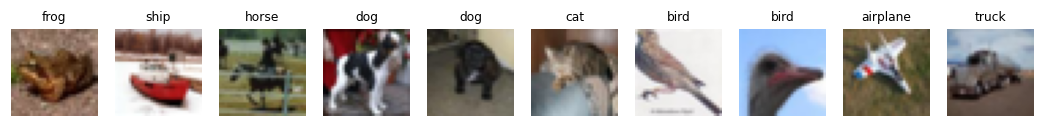

In [ ]:
root = './data'
train_full = torchvision.datasets.CIFAR10(root, train=True, download=True)
classes = train_full.classes

X_all = torch.tensor(train_full.data).permute(0, 3, 1, 2).float().div(255)   # (50000, 3, 32, 32)
y_all = torch.tensor(train_full.targets)

g = torch.Generator().manual_seed(0)
perm = torch.randperm(len(X_all), generator=g)
tr_idx, va_idx = perm[:45000], perm[45000:]

mean = X_all[tr_idx].mean(dim=(0, 2, 3))
std  = X_all[tr_idx].std(dim=(0, 2, 3))
print('channel mean:', mean.numpy().round(4), ' channel std:', std.numpy().round(4))

def normalize(x):
    return (x - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)

Xtr, ytr = normalize(X_all[tr_idx]).to(device), y_all[tr_idx].to(device)
Xva, yva = normalize(X_all[va_idx]).to(device), y_all[va_idx].to(device)
print('train:', tuple(Xtr.shape), ' val:', tuple(Xva.shape))

# show a few training images
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for k, ax in enumerate(axes):
    ax.imshow(X_all[tr_idx[k]].permute(1, 2, 0).numpy())
    ax.set_title(classes[y_all[tr_idx[k]]], fontsize=8)
    ax.axis('off')
plt.show()
del X_all

### Shared helpers
GPU augmentations (random crop with 4-pixel padding, horizontal flip, cutout, mixup), an evaluation function, a learning-rate schedule and one general training loop that every task uses.
**Cutout** and **mixup** are written by hand here (as Task 3 asks).

In [ ]:
# ---------------- augmentations (work on a whole batch on the GPU) ----------------
def random_crop(x, pad=4):
    # pad with zeros (= the mean colour after normalisation), then cut a random 32x32 window
    N, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    rows = i[:, None] + torch.arange(H, device=x.device)          # (N, H)
    cols = j[:, None] + torch.arange(W, device=x.device)          # (N, W)
    n_idx = torch.arange(N, device=x.device)[:, None, None, None]
    c_idx = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[n_idx, c_idx, rows[:, None, :, None], cols[:, None, None, :]]

def random_flip(x):
    mask = torch.rand(x.shape[0], device=x.device) < 0.5
    return torch.where(mask[:, None, None, None], x.flip(3), x)

def cutout(x, size=16):
    # set one random size x size square in every image to zero (the square may stick out of the image)
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N,), device=x.device)
    cx = torch.randint(0, W, (N,), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :]
    xs = torch.arange(W, device=x.device)[None, :]
    rmask = (ys >= cy[:, None] - size // 2) & (ys < cy[:, None] + size // 2)   # (N, H)
    cmask = (xs >= cx[:, None] - size // 2) & (xs < cx[:, None] + size // 2)   # (N, W)
    hole = rmask[:, :, None] & cmask[:, None, :]                               # (N, H, W)
    return x * (~hole)[:, None].to(x.dtype)

def mixup(x, y, alpha):
    # blend every image with another random image from the batch; labels are blended with the same weight
    lam = float(np.random.beta(alpha, alpha))
    idx = torch.randperm(x.shape[0], device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam

# ---------------- evaluation ----------------
@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval()
    correct, loss_sum = 0, 0.0
    for i in range(0, len(X), bs):
        xb, yb = X[i:i + bs], y[i:i + bs]
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == 'cuda')):
            out = model(xb)
        loss_sum += F.cross_entropy(out.float(), yb, reduction='sum').item()
        correct += (out.argmax(1) == yb).sum().item()
    return correct / len(X), loss_sum / len(X)

# ---------------- learning-rate schedule (multiplier of the base lr, per iteration) ----------------
def make_schedule(kind, total_steps, warmup_steps=0):
    def f(step):
        if kind == 'constant':
            return 1.0
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
        if kind == 'cosine':
            return 0.5 * (1 + math.cos(math.pi * progress))
        if kind == 'linear':
            return max(0.0, 1.0 - progress)
        raise ValueError(kind)
    return f

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def smooth(v, k=50):
    v = np.asarray(v, dtype=float)
    if len(v) < k:
        return v
    return np.convolve(v, np.ones(k) / k, mode='valid')

# ---------------- general training loop ----------------
def train_model(model, X, y, epochs, make_opt, bs=128, aug=None, mixup_alpha=0.0,
                schedule='constant', warmup_epochs=0, label_smoothing=0.0, amp=True,
                eval_train=False, Xv=None, yv=None, verbose=True, tag=''):
    aug = aug or {}
    model.to(device)
    opt = make_opt(model.parameters())
    steps_per_epoch = math.ceil(len(X) / bs)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, make_schedule(schedule, epochs * steps_per_epoch, warmup_epochs * steps_per_epoch))
    use_amp = amp and device.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    hist = {'train_loss': [], 'train_acc_running': [], 'train_acc': [], 'val_acc': [],
            'val_loss': [], 'iter_loss': [], 'diverged': False}
    print_every = max(1, epochs // 5)
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X), device=X.device)
        loss_sum = torch.zeros((), device=X.device)
        correct = torch.zeros((), device=X.device)
        seen, iter_l = 0, []
        for k in range(0, len(X), bs):
            idx = perm[k:k + bs]
            xb, yb = X[idx], y[idx]
            if aug.get('crop'):   xb = random_crop(xb)
            if aug.get('flip'):   xb = random_flip(xb)
            if aug.get('cutout'): xb = cutout(xb, aug['cutout'])
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                if mixup_alpha > 0:
                    xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
                    out = model(xb)
                    loss = (lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing)
                            + (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=label_smoothing))
                else:
                    out = model(xb)
                    loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            l = loss.detach().float()
            iter_l.append(l)
            loss_sum += l * len(idx)
            correct += (out.argmax(1) == yb).sum()
            seen += len(idx)
        ep_loss = loss_sum.item() / seen
        hist['iter_loss'] += torch.stack(iter_l).cpu().tolist()
        hist['train_loss'].append(ep_loss)
        hist['train_acc_running'].append(correct.item() / seen)
        if eval_train:
            hist['train_acc'].append(evaluate(model, X, y)[0])
        if Xv is not None:
            va, vl = evaluate(model, Xv, yv)
            hist['val_acc'].append(va); hist['val_loss'].append(vl)
        if verbose and (ep % print_every == 0 or ep == epochs - 1):
            msg = f'{tag} epoch {ep + 1:3d}/{epochs}  train loss {ep_loss:.4f}'
            if eval_train: msg += f'  train acc {hist["train_acc"][-1]:.4f}'
            if Xv is not None: msg += f'  val acc {hist["val_acc"][-1]:.4f}'
            print(msg + f'  ({time.time() - t0:.0f}s)')
        if not math.isfinite(ep_loss):
            hist['diverged'] = True
            if verbose: print(f'{tag} loss became NaN/inf -> diverged, stopping')
            break
    hist['time'] = time.time() - t0
    return hist

---
## Task 1: Backpropagation

### (a) Layers with hand-written forward and backward passes (no autograd)

For a batch of $N$ inputs:

* **Linear:** $Y = XW^\top + b$.  Backward: $\frac{\partial L}{\partial W} = \delta^\top X$, $\frac{\partial L}{\partial b} = \sum_n \delta_n$, $\frac{\partial L}{\partial X} = \delta W$, where $\delta = \partial L/\partial Y$.
* **ReLU:** $y = \max(0, x)$. Backward: pass the gradient only where $x > 0$.
* **Sigmoid** (needed for part d): $s = 1/(1+e^{-x})$. Backward: multiply by $s(1-s)$.
* **Softmax + cross-entropy:** $L = -\frac1N\sum_n \log p_{n,y_n}$. Backward has a very simple form: $\frac{\partial L}{\partial z} = \frac1N(p - \text{onehot}(y))$.

In [ ]:
class Linear:
    def __init__(self, in_f, out_f, init='kaiming', dtype=torch.float32, device=device):
        if init == 'kaiming':  std = math.sqrt(2.0 / in_f)            # good for ReLU
        elif init == 'xavier': std = math.sqrt(2.0 / (in_f + out_f))  # good for sigmoid / tanh
        else:                  std = 0.01
        self.W = torch.randn(out_f, in_f, dtype=dtype, device=device) * std
        self.b = torch.zeros(out_f, dtype=dtype, device=device)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)
    def forward(self, x):
        self.x = x                         # keep the input for the backward pass
        return x @ self.W.T + self.b
    def backward(self, dout):
        self.dW = dout.T @ self.x
        self.db = dout.sum(0)
        return dout @ self.W               # gradient for the layer below
    def params(self): return [self.W, self.b]
    def grads(self):  return [self.dW, self.db]

class ReLU:
    def forward(self, x):
        self.mask = (x > 0).to(x.dtype)
        return x * self.mask
    def backward(self, dout):
        return dout * self.mask

class Sigmoid:
    def forward(self, x):
        self.s = 1.0 / (1.0 + torch.exp(-x))
        return self.s
    def backward(self, dout):
        return dout * self.s * (1 - self.s)

class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values          # for numerical stability
        logp = z - torch.log(torch.exp(z).sum(dim=1, keepdim=True))  # log-softmax
        self.probs, self.y = torch.exp(logp), y
        N = logits.shape[0]
        return -logp[torch.arange(N, device=logits.device), y].mean()
    def backward(self):
        N = self.probs.shape[0]
        d = self.probs.clone()
        d[torch.arange(N, device=d.device), self.y] -= 1
        return d / N

class MLP:
    def __init__(self, sizes, act='relu', init='kaiming', dtype=torch.float32, device=device):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init, dtype, device))
            if i < len(sizes) - 2:                       # no activation after the last layer
                self.layers.append(ReLU() if act == 'relu' else Sigmoid())
        self.loss_fn = SoftmaxCrossEntropy()
    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x
    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)
    def backward(self):
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)
        return d                                         # gradient w.r.t. the input
    def linears(self): return [l for l in self.layers if isinstance(l, Linear)]
    def params(self):  return [p for l in self.linears() for p in l.params()]
    def grads(self):   return [g for l in self.linears() for g in l.grads()]

### (b) Gradient check against autograd and centred finite differences
A small network (20 -> 16 -> 12 -> 5) in **float64** on a batch of 8 random inputs.
Relative error $= \dfrac{\lVert g_1 - g_2\rVert}{\lVert g_1\rVert + \lVert g_2\rVert}$.
Finite difference: $\dfrac{L(\theta+\varepsilon) - L(\theta-\varepsilon)}{2\varepsilon}$ with $\varepsilon = 10^{-6}$, done for every single weight.

In [ ]:
def rel_err(a, b):
    return ((a - b).norm() / max((a.norm() + b.norm()).item(), 1e-20)).item()

def numerical_grads(net, x, y, eps=1e-6):
    grads = []
    for p in net.params():
        g = torch.zeros_like(p)
        flat, gflat = p.view(-1), g.view(-1)
        for k in range(flat.numel()):
            old = flat[k].item()
            flat[k] = old + eps; lp = net.loss(x, y).item()
            flat[k] = old - eps; lm = net.loss(x, y).item()
            flat[k] = old
            gflat[k] = (lp - lm) / (2 * eps)
        grads.append(g)
    return grads

def grad_check(act='relu'):
    set_seed(0)
    dt = torch.float64
    net = MLP([20, 16, 12, 5], act=act, dtype=dt, device='cpu')
    x = torch.randn(8, 20, dtype=dt)
    y = torch.randint(0, 5, (8,))

    # 1) my backward pass
    net.loss(x, y)
    dx_manual = net.backward()
    manual = [g.clone() for g in net.grads()]

    # 2) the same network written with torch ops, gradients from autograd
    ps = [p.clone().requires_grad_(True) for p in net.params()]
    xa = x.clone().requires_grad_(True)
    h, n_lin = xa, len(ps) // 2
    for i in range(n_lin):
        h = h @ ps[2 * i].T + ps[2 * i + 1]
        if i < n_lin - 1:
            h = torch.relu(h) if act == 'relu' else torch.sigmoid(h)
    F.cross_entropy(h, y).backward()
    auto = [p.grad for p in ps]

    # 3) centred finite differences
    num = numerical_grads(net, x, y)

    names = [f'{t}{i + 1}' for i in range(n_lin) for t in ('W', 'b')]
    rows = []
    for name, gm, ga, gn in zip(names, manual, auto, num):
        rows.append({'param': name, 'shape': tuple(gm.shape),
                     'rel err vs autograd': rel_err(gm, ga),
                     'allclose (autograd)': torch.allclose(gm, ga),
                     'rel err vs finite diff': rel_err(gm, gn),
                     'allclose (finite diff)': torch.allclose(gm, gn, rtol=1e-4, atol=1e-7)})
    rows.append({'param': 'input x', 'shape': tuple(x.shape),
                 'rel err vs autograd': rel_err(dx_manual, xa.grad),
                 'allclose (autograd)': torch.allclose(dx_manual, xa.grad),
                 'rel err vs finite diff': float('nan'), 'allclose (finite diff)': None})
    return pd.DataFrame(rows)

pd.set_option('display.float_format', lambda v: f'{v:.2e}')
print('ReLU network'); display(grad_check('relu'))
print('Sigmoid network (the Sigmoid layer is also used in part d)'); display(grad_check('sigmoid'))
pd.reset_option('display.float_format')

ReLU network


,param,shape,rel err vs autograd,allclose (autograd),rel err vs finite diff,allclose (finite diff)
0,W1,"(16, 20)",9.75e-17,True,8.19e-10,True
1,b1,"(16,)",1.25e-16,True,8.31e-10,True
2,W2,"(12, 16)",4.65e-17,True,5.67e-10,True
3,b2,"(12,)",4.55e-17,True,7.26e-10,True
4,W3,"(5, 12)",4.97e-17,True,3.66e-10,True
5,b3,"(5,)",7.82e-17,True,5.61e-10,True
6,input x,"(8, 20)",1.11e-16,True,NaN,None


Sigmoid network (the Sigmoid layer is also used in part d)


,param,shape,rel err vs autograd,allclose (autograd),rel err vs finite diff,allclose (finite diff)
0,W1,"(16, 20)",1.05e-16,True,5.21e-09,True
1,b1,"(16,)",1.19e-16,True,7.27e-09,True
2,W2,"(12, 16)",6.52e-17,True,2.44e-09,True
3,b2,"(12,)",8.11e-17,True,1.46e-09,True
4,W3,"(5, 12)",6.28e-17,True,6.28e-10,True
5,b3,"(5,)",6.63e-17,True,6.73e-11,True
6,input x,"(8, 20)",9.06e-17,True,NaN,None


**Discussion.** My gradients match autograd almost exactly. The relative errors are about $10^{-15}$ or smaller, which is just rounding error. The errors against finite differences are a bit bigger, because finite differences are only an approximation. They are still very small. `torch.allclose` is `True` for every layer. So my backward passes are correct.

### (c) Train the MLP with plain SGD on flattened CIFAR-10
Network: 3072 -> 512 -> 256 -> 10 with ReLU, Kaiming initialisation. Plain SGD (no momentum), learning rate 0.02, batch size 128. The update $\theta \leftarrow \theta - \eta \nabla_\theta L$ is written by hand.

epoch  1  train loss 1.7511  val acc 0.4228  (1s)
epoch  2  train loss 1.4750  val acc 0.4452  (1s)
epoch  3  train loss 1.3516  val acc 0.4566  (2s)
epoch  4  train loss 1.2588  val acc 0.4850  (2s)
epoch  5  train loss 1.1833  val acc 0.4842  (3s)
epoch  6  train loss 1.1131  val acc 0.4994  (3s)
epoch  7  train loss 1.0521  val acc 0.4948  (3s)
epoch  8  train loss 0.9928  val acc 0.4950  (4s)
epoch  9  train loss 0.9308  val acc 0.4972  (4s)
epoch 10  train loss 0.8839  val acc 0.4980  (5s)
epoch 11  train loss 0.8302  val acc 0.5014  (5s)
epoch 12  train loss 0.7825  val acc 0.4984  (5s)
epoch 13  train loss 0.7344  val acc 0.4978  (6s)
epoch 14  train loss 0.6848  val acc 0.5066  (6s)
epoch 15  train loss 0.6473  val acc 0.5122  (7s)
epoch 16  train loss 0.6011  val acc 0.4978  (7s)
epoch 17  train loss 0.5623  val acc 0.5058  (8s)
epoch 18  train loss 0.5246  val acc 0.5000  (8s)
epoch 19  train loss 0.4889  val acc 0.4950  (8s)
epoch 20  train loss 0.4523  val acc 0.4872  (9s)


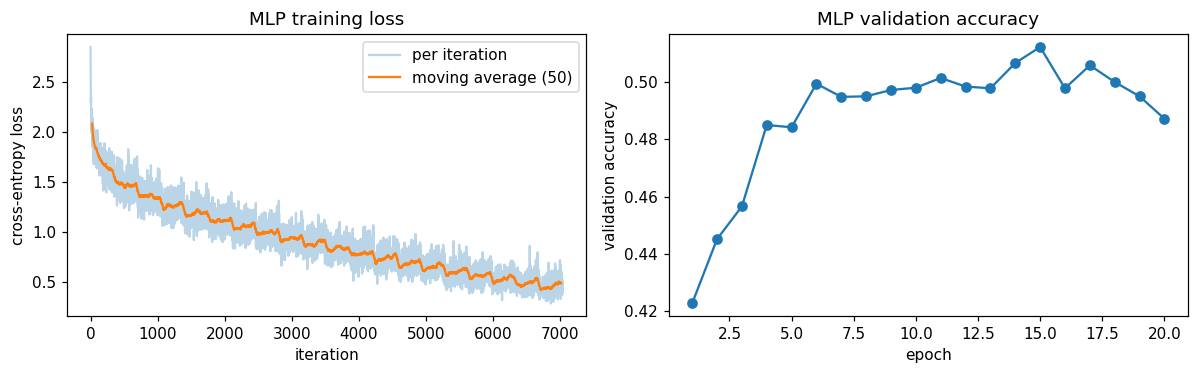

Final validation accuracy of the MLP: 0.4872


In [ ]:
set_seed(0)
mlp = MLP([3072, 512, 256, 10], act='relu')
Xtr_f, Xva_f = Xtr.reshape(len(Xtr), -1), Xva.reshape(len(Xva), -1)
lr, bs, epochs = 0.02, 128, E(20)
mlp_iter_loss, mlp_ep_loss, mlp_val_acc = [], [], []
t0 = time.time()
for ep in range(epochs):
    perm = torch.randperm(len(Xtr_f), device=device)
    s = 0.0
    for k in range(0, len(perm), bs):
        idx = perm[k:k + bs]
        loss = mlp.loss(Xtr_f[idx], ytr[idx])
        mlp.backward()
        for p, g in zip(mlp.params(), mlp.grads()):
            p -= lr * g                                  # SGD step, done by hand
        mlp_iter_loss.append(loss.item())
        s += loss.item() * len(idx)
    mlp_ep_loss.append(s / len(Xtr_f))
    acc = (mlp.forward(Xva_f).argmax(1) == yva).float().mean().item()
    mlp_val_acc.append(acc)
    print(f'epoch {ep + 1:2d}  train loss {mlp_ep_loss[-1]:.4f}  val acc {acc:.4f}  ({time.time() - t0:.0f}s)')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(mlp_iter_loss, alpha=0.3, label='per iteration')
ax[0].plot(np.arange(len(smooth(mlp_iter_loss))) + 25, smooth(mlp_iter_loss), label='moving average (50)')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('cross-entropy loss'); ax[0].set_title('MLP training loss'); ax[0].legend()
ax[1].plot(range(1, epochs + 1), mlp_val_acc, 'o-')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('validation accuracy'); ax[1].set_title('MLP validation accuracy')
plt.tight_layout(); plt.show()
print(f'Final validation accuracy of the MLP: {mlp_val_acc[-1]:.4f}')

**Discussion.** The loss drops quickly at first and then slows down. The curve is noisy because each batch is different. The MLP reaches about 50% validation accuracy. This is much better than guessing (10%), but it is still low. The MLP flattens the image, so it loses the 2-D layout of the pixels. It cannot easily find the same pattern in different places. This is why the CNNs in later tasks do much better.

### (d) Gradient norm per layer at initialisation – 10-layer MLP, sigmoid vs ReLU
Network: 3072 -> 256 × 9 -> 10 (10 Linear layers). One forward and backward pass on 512 training images, at initialisation (no training). I plot $\lVert \partial L/\partial W_\ell\rVert$ for every layer $\ell$ (layer 1 = next to the input).
Each activation uses its usual initialisation (Xavier for sigmoid, Kaiming for ReLU). I also add sigmoid with Kaiming initialisation, to show that the problem comes from the activation and not from the initialisation.

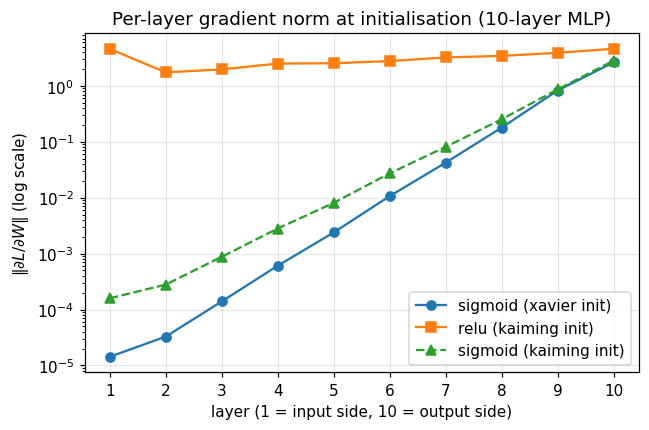

,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6,layer 7,layer 8,layer 9,layer 10
sigmoid (xavier init),1.4e-05,3.3e-05,1.4e-04,6.1e-04,2.4e-03,1.1e-02,4.2e-02,1.8e-01,8.3e-01,2.6e+00
relu (kaiming init),4.6e+00,1.7e+00,2.0e+00,2.5e+00,2.5e+00,2.8e+00,3.2e+00,3.4e+00,3.9e+00,4.6e+00
sigmoid (kaiming init),1.6e-04,2.8e-04,8.8e-04,2.8e-03,8.1e-03,2.7e-02,8.1e-02,2.5e-01,8.6e-01,2.8e+00


In [ ]:
xb, yb = Xtr_f[:512], ytr[:512]
norms = {}
for act, init in [('sigmoid', 'xavier'), ('relu', 'kaiming'), ('sigmoid', 'kaiming')]:
    set_seed(0)
    deep = MLP([3072] + [256] * 9 + [10], act=act, init=init)
    deep.loss(xb, yb)
    deep.backward()
    norms[f'{act} ({init} init)'] = [l.dW.norm().item() for l in deep.linears()]

plt.figure(figsize=(6.5, 4))
for (name, v), st in zip(norms.items(), ['o-', 's-', '^--']):
    plt.semilogy(range(1, 11), v, st, label=name)
plt.xlabel('layer (1 = input side, 10 = output side)'); plt.ylabel(r'$\|\partial L/\partial W\|$ (log scale)')
plt.title('Per-layer gradient norm at initialisation (10-layer MLP)'); plt.xticks(range(1, 11)); plt.legend(); plt.grid(alpha=0.3)
plt.show()
display(pd.DataFrame(norms, index=[f'layer {i}' for i in range(1, 11)]).T.style.format('{:.1e}'))

**Discussion.** With sigmoid, the gradient gets smaller as we move back towards the input. Layer 1 gets a much smaller gradient than layer 10. This is the vanishing gradient problem. The derivative of sigmoid is at most 0.25. The chain rule multiplies these values layer by layer, so the gradient shrinks very fast.

With ReLU and Kaiming init, the gradient stays about the same size in every layer. ReLU has a derivative of 1 when it is active, so the gradient does not shrink. Sigmoid with Kaiming init still vanishes. So the main problem is the activation, not the initialisation.

---
## Task 2: Optimizers

### (a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses
* **SGD (+ momentum):** $g \leftarrow \nabla L + \lambda\theta$, $\;v \leftarrow \mu v + g$, $\;\theta \leftarrow \theta - \eta v$ (with $\mu = 0$ this is plain SGD). This is the same convention as `torch.optim.SGD` (no dampening, and on the first step $v = g$).
* **Adam:** $m \leftarrow \beta_1 m + (1-\beta_1)g$, $\;v \leftarrow \beta_2 v + (1-\beta_2)g^2$, bias correction $\hat m = m/(1-\beta_1^t)$, $\hat v = v/(1-\beta_2^t)$, then $\theta \leftarrow \theta - \eta\,\hat m/(\sqrt{\hat v} + \epsilon)$.

In [ ]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd = group['lr'], group['momentum'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                if mu != 0:
                    state = self.state[p]
                    if 'momentum_buffer' not in state:
                        state['momentum_buffer'] = g.clone().detach()
                    else:
                        state['momentum_buffer'].mul_(mu).add_(g)
                    g = state['momentum_buffer']
                p.add_(g, alpha=-lr)
        return loss

class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group['lr'], group['betas'], group['eps'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['step'] += 1
                t, m, v = state['step'], state['m'], state['v']
                m.mul_(b1).add_(g, alpha=1 - b1)              # 1st moment (mean of gradients)
                v.mul_(b2).addcmul_(g, g, value=1 - b2)       # 2nd moment (mean of squared gradients)
                m_hat = m / (1 - b1 ** t)                     # bias correction
                v_hat = v / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)
        return loss

def compare_with_torch(MyOpt, TorchOpt, kwargs, steps=100):
    set_seed(0)
    m1 = nn.Sequential(nn.Linear(20, 32), nn.ReLU(), nn.Linear(32, 10)).double()
    m2 = copy.deepcopy(m1)                      # identical starting weights
    o1, o2 = MyOpt(m1.parameters(), **kwargs), TorchOpt(m2.parameters(), **kwargs)
    for _ in range(steps):
        x = torch.randn(64, 20, dtype=torch.float64)
        y = torch.randint(0, 10, (64,))
        for m, o in [(m1, o1), (m2, o2)]:
            o.zero_grad()
            F.cross_entropy(m(x), y).backward()
            o.step()
    max_diff = max((p1 - p2).abs().max().item() for p1, p2 in zip(m1.parameters(), m2.parameters()))
    same = all(torch.allclose(p1, p2) for p1, p2 in zip(m1.parameters(), m2.parameters()))
    return max_diff, same

tests = [('SGD (plain)',        MySGD,  torch.optim.SGD,  dict(lr=0.1)),
         ('SGD momentum + wd',  MySGD,  torch.optim.SGD,  dict(lr=0.05, momentum=0.9, weight_decay=5e-4)),
         ('Adam',               MyAdam, torch.optim.Adam, dict(lr=1e-3)),
         ('Adam + wd',          MyAdam, torch.optim.Adam, dict(lr=3e-3, betas=(0.8, 0.99), weight_decay=1e-3))]
rows = []
for name, mine, ref, kw in tests:
    d, ok = compare_with_torch(mine, ref, kw)
    rows.append({'optimizer': name, 'settings': str(kw), 'max |param difference| after 100 steps': f'{d:.2e}', 'torch.allclose': ok})
display(pd.DataFrame(rows))

,optimizer,settings,max |param difference| after 100 steps,torch.allclose
0,SGD (plain),{'lr': 0.1},0.00e+00,True
1,SGD momentum + wd,"{'lr': 0.05, 'momentum': 0.9, 'weight_decay': ...",0.00e+00,True
2,Adam,{'lr': 0.001},8.33e-17,True
3,Adam + wd,"{'lr': 0.003, 'betas': (0.8, 0.99), 'weight_de...",1.11e-16,True


**Discussion.** Both networks started from the same weights and saw the same data. After 100 steps, the largest weight difference is about $10^{-15}$. This is only rounding error. `torch.allclose` is `True` in every case. So my SGD, momentum and Adam give the same updates as PyTorch.

### (b) Trajectories on $f(x,y) = \tfrac12(x^2 + 50y^2)$
The function is 50 times steeper in $y$ than in $x$ (Hessian eigenvalues 1 and 50). Start at $(-9, 1.5)$, 100 steps.
Settings: SGD $\eta=0.035$ (close to the stability limit $2/50 = 0.04$), SGD + momentum $\eta=0.02$, $\mu=0.9$, Adam $\eta=0.3$.

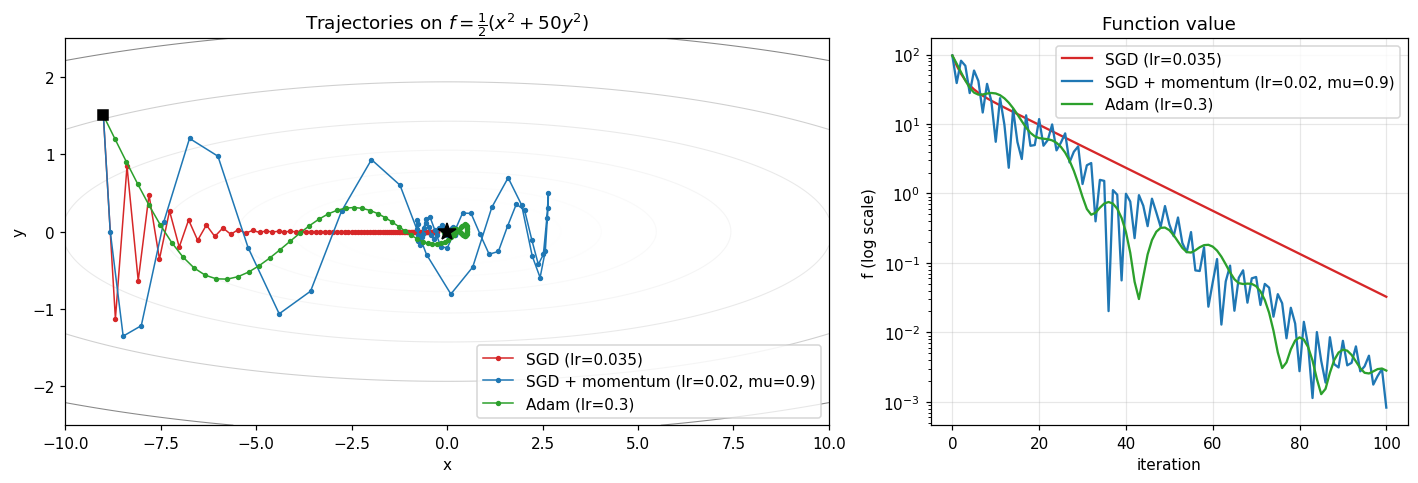

SGD (lr=0.035)                      f after 10 / 30 / 100 steps: 2.00e+01 / 4.78e+00 / 3.26e-02
SGD + momentum (lr=0.02, mu=0.9)    f after 10 / 30 / 100 steps: 5.55e+00 / 1.37e+00 / 8.27e-04
Adam (lr=0.3)                       f after 10 / 30 / 100 steps: 2.76e+01 / 8.92e-01 / 2.82e-03


In [ ]:
def run_quadratic(opt_cls, steps=100, start=(-9.0, 1.5), **kw):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_cls([p], **kw)
    path = [p.detach().clone()]
    for _ in range(steps):
        opt.zero_grad()
        f = 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)
        f.backward()
        opt.step()
        path.append(p.detach().clone())
    return torch.stack(path).numpy()

quad_runs = {'SGD (lr=0.035)':                   run_quadratic(MySGD, lr=0.035),
             'SGD + momentum (lr=0.02, mu=0.9)': run_quadratic(MySGD, lr=0.02, momentum=0.9),
             'Adam (lr=0.3)':                    run_quadratic(MyAdam, lr=0.3)}

xs, ys = np.linspace(-10, 10, 400), np.linspace(-2.5, 2.5, 400)
XX, YY = np.meshgrid(xs, ys)
ZZ = 0.5 * (XX ** 2 + 50 * YY ** 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].contour(XX, YY, ZZ, levels=np.logspace(-2, 2.5, 18), cmap='Greys', linewidths=0.7)
for (name, P), c in zip(quad_runs.items(), ['tab:red', 'tab:blue', 'tab:green']):
    ax[0].plot(P[:, 0], P[:, 1], 'o-', ms=2.5, lw=1, color=c, label=name)
ax[0].plot(0, 0, 'k*', ms=12); ax[0].plot(-9, 1.5, 'ks', ms=6)
ax[0].set_xlabel('x'); ax[0].set_ylabel('y'); ax[0].set_title(r'Trajectories on $f=\frac{1}{2}(x^2+50y^2)$'); ax[0].legend(loc='lower right')
for (name, P), c in zip(quad_runs.items(), ['tab:red', 'tab:blue', 'tab:green']):
    ax[1].semilogy(0.5 * (P[:, 0] ** 2 + 50 * P[:, 1] ** 2) + 1e-12, color=c, label=name)
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('f (log scale)'); ax[1].set_title('Function value'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
for name, P in quad_runs.items():
    print(f'{name:35s} f after 10 / 30 / 100 steps: '
          + ' / '.join(f'{0.5 * (P[k, 0] ** 2 + 50 * P[k, 1] ** 2):.2e}' for k in (10, 30, 100)))

**Discussion.** The function is 50 times steeper in $y$ than in $x$.

* **SGD** zig-zags in $y$ and moves slowly in $x$. The learning rate has to be small because of the steep $y$ direction. But that small rate makes progress in $x$ very slow.
* **Momentum** reduces the zig-zag. The $y$ gradients keep changing sign, so they cancel out. The $x$ gradients always point the same way, so they add up. It moves faster along the valley, but it overshoots a little near the minimum.
* **Adam** scales each direction by its own gradient size. So it takes similar steps in $x$ and $y$ and goes more directly to the minimum. Near the end it wobbles a bit because the learning rate is fixed.

Momentum and Adam reach a much lower value than plain SGD in the same number of steps.

### (c) Small CNN with each optimizer at three learning rates
A small CNN without batch norm: [conv 32 → conv 32 → pool → conv 64 → conv 64 → pool → conv 128 → pool → FC 256 → FC 10].
The same learning-rate grid {1e-3, 1e-2, 1e-1} for all three optimizers (my own implementations from part a). 10 epochs, batch 128, constant learning rate, full 45k training set. Mixed precision is turned off here so that real divergence can be seen.

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, bn=False, p_drop=0.0):
        super().__init__()
        def block(ci, co):
            layers = [nn.Conv2d(ci, co, 3, padding=1, bias=not bn)]
            if bn:
                layers.append(nn.BatchNorm2d(co))
            layers.append(nn.ReLU(inplace=True))
            return layers
        self.features = nn.Sequential(*block(3, 32), *block(32, 32), nn.MaxPool2d(2),
                                      *block(32, 64), *block(64, 64), nn.MaxPool2d(2),
                                      *block(64, 128), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop), nn.Linear(128 * 4 * 4, 256),
                                        nn.ReLU(inplace=True), nn.Dropout(p_drop), nn.Linear(256, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

print('SmallCNN parameters:', count_params(SmallCNN()))

lrs = [1e-3, 1e-2, 1e-1]
opt_makers = {
    'SGD':          lambda lr: (lambda ps: MySGD(ps, lr=lr)),
    'SGD+momentum': lambda lr: (lambda ps: MySGD(ps, lr=lr, momentum=0.9)),
    'Adam':         lambda lr: (lambda ps: MyAdam(ps, lr=lr)),
}
sweep = {}
for name, mk in opt_makers.items():
    for lr in lrs:
        set_seed(0)
        h = train_model(SmallCNN(), Xtr, ytr, E(10), mk(lr), bs=128, amp=False, Xv=Xva, yv=yva, verbose=False)
        sweep[(name, lr)] = h
        print(f'{name:13s} lr={lr:<6g} final val acc {h["val_acc"][-1]:.4f}  best {max(h["val_acc"]):.4f}'
              f'  final train loss {h["train_loss"][-1]:.4f}' + ('  (DIVERGED)' if h['diverged'] else '')
              + f'  [{h["time"]:.0f}s]')

SmallCNN parameters: 666538
SGD           lr=0.001  final val acc 0.1354  best 0.1406  final train loss 2.3011  [38s]
SGD           lr=0.01   final val acc 0.4512  best 0.4560  final train loss 1.4719  [36s]
SGD           lr=0.1    final val acc 0.6758  best 0.7144  final train loss 0.4561  [37s]
SGD+momentum  lr=0.001  final val acc 0.4668  best 0.4668  final train loss 1.4459  [38s]
SGD+momentum  lr=0.01   final val acc 0.7512  best 0.7584  final train loss 0.3344  [38s]
SGD+momentum  lr=0.1    final val acc 0.5244  best 0.5786  final train loss 1.3549  [37s]
Adam          lr=0.001  final val acc 0.7462  best 0.7634  final train loss 0.1914  [39s]
Adam          lr=0.01   final val acc 0.0964  best 0.1016  final train loss 2.3033  [36s]
Adam          lr=0.1    final val acc 0.1012  best 0.1014  final train loss 2.3080  [36s]


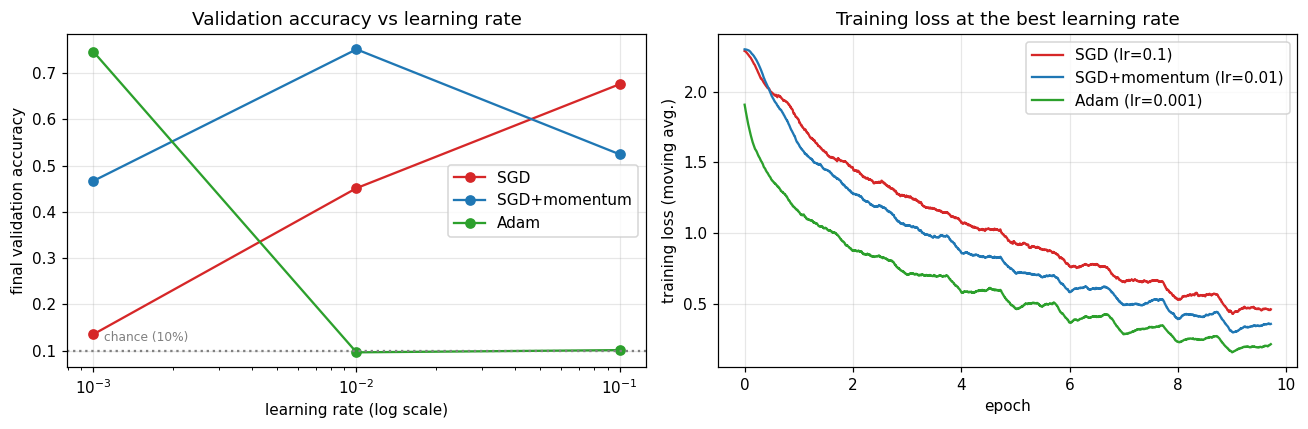

,lr=0.001,lr=0.01,lr=0.1
SGD,0.1354,0.4512,0.6758
SGD+momentum,0.4668,0.7512,0.5244
Adam,0.7462,0.0964,0.1012


In [ ]:
colors = {'SGD': 'tab:red', 'SGD+momentum': 'tab:blue', 'Adam': 'tab:green'}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
best_lr = {}
for name in opt_makers:
    accs = [sweep[(name, lr)]['val_acc'][-1] for lr in lrs]
    ax[0].semilogx(lrs, accs, 'o-', color=colors[name], label=name)
    best_lr[name] = lrs[int(np.argmax(accs))]
ax[0].axhline(0.1, ls=':', color='grey'); ax[0].text(1.1e-3, 0.12, 'chance (10%)', color='grey', fontsize=8)
ax[0].set_xlabel('learning rate (log scale)'); ax[0].set_ylabel('final validation accuracy')
ax[0].set_title('Validation accuracy vs learning rate'); ax[0].legend(); ax[0].grid(alpha=0.3)
for name in opt_makers:
    h = sweep[(name, best_lr[name])]
    il = smooth(h['iter_loss'], 100)
    ax[1].plot(np.arange(len(il)) / math.ceil(len(Xtr) / 128), il, color=colors[name], label=f'{name} (lr={best_lr[name]:g})')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('training loss (moving avg.)'); ax[1].set_title('Training loss at the best learning rate')
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

table = pd.DataFrame({name: [sweep[(name, lr)]['val_acc'][-1] for lr in lrs] for name in opt_makers},
                     index=[f'lr={lr:g}' for lr in lrs]).T
display(table.style.format('{:.4f}').highlight_max(axis=1, color='lightgreen'))

**Discussion.** Each optimizer works best at a different learning rate.

* **Plain SGD** does best at 0.1 (67.6%). At 0.001 it learns very little in 10 epochs (13.5%).
* **SGD with momentum** does best at 0.01 (75.1%). Momentum makes the steps about 10 times bigger, so at 0.1 training becomes unstable and accuracy falls to 52.4%.
* **Adam** does best at 0.001 (74.6%). At 0.01 and 0.1 it fails completely and stays at about 10%.

All three are sensitive to the learning rate, and Adam is the most sensitive. The rate must be tuned again whenever the optimizer changes. At their best rates, momentum and Adam do much better than plain SGD.

---
## Task 3: Regularization and residual connections

### (a) Regularization on only 5k training images
The same small CNN as Task 2 **with batch norm**, trained on only the first 5,000 training images, so it overfits easily. Every run uses SGD with Nesterov momentum 0.9, learning rate 0.05 with cosine decay (2 warm-up epochs), batch 128, 60 epochs.
Settings: weight decay $5\times10^{-4}$; dropout $p = 0.5$ in the classifier; flip + random crop (4-pixel padding); cutout 16×16 (my own function); mixup $\alpha = 0.4$ (my own function); and all of them together.
**Train accuracy is measured on the clean 5k training images** (no augmentation, eval mode), so the train–validation gap is a fair measure of overfitting.

In [ ]:
Xs, ys = Xtr[:5000], ytr[:5000]
reg_configs = {
    'baseline':     dict(),
    'weight decay': dict(wd=5e-4),
    'dropout':      dict(p_drop=0.5),
    'flip+crop':    dict(aug={'flip': True, 'crop': True}),
    'cutout':       dict(aug={'cutout': 16}),
    'mixup':        dict(mixup=0.4),
    'all combined': dict(wd=5e-4, p_drop=0.5, aug={'flip': True, 'crop': True, 'cutout': 16}, mixup=0.4),
}
reg_hist = {}
for name, cfg in reg_configs.items():
    set_seed(0)
    model = SmallCNN(bn=True, p_drop=cfg.get('p_drop', 0.0))
    wd = cfg.get('wd', 0.0)
    h = train_model(model, Xs, ys, E(60),
                    lambda ps, wd=wd: torch.optim.SGD(ps, lr=0.05, momentum=0.9, nesterov=True, weight_decay=wd),
                    bs=128, aug=cfg.get('aug'), mixup_alpha=cfg.get('mixup', 0.0),
                    schedule='cosine', warmup_epochs=2, eval_train=True, Xv=Xva, yv=yva, verbose=False)
    reg_hist[name] = h
    print(f'{name:13s} train acc {h["train_acc"][-1]:.4f}  val acc {h["val_acc"][-1]:.4f}'
          f'  gap {h["train_acc"][-1] - h["val_acc"][-1]:.4f}  [{h["time"]:.0f}s]')

baseline      train acc 1.0000  val acc 0.6760  gap 0.3240  [27s]
weight decay  train acc 1.0000  val acc 0.6812  gap 0.3188  [24s]
dropout       train acc 0.9910  val acc 0.7156  gap 0.2754  [24s]
flip+crop     train acc 0.9650  val acc 0.7652  gap 0.1998  [25s]
cutout        train acc 1.0000  val acc 0.7148  gap 0.2852  [25s]
mixup         train acc 1.0000  val acc 0.6872  gap 0.3128  [25s]
all combined  train acc 0.6984  val acc 0.6432  gap 0.0552  [27s]


,train acc,val acc,gap (train - val),best val acc
setting,,,,
baseline,1.0000,0.6760,0.3240,0.6824
weight decay,1.0000,0.6812,0.3188,0.6872
dropout,0.9910,0.7156,0.2754,0.7182
flip+crop,0.9650,0.7652,0.1998,0.7652
cutout,1.0000,0.7148,0.2852,0.7170
mixup,1.0000,0.6872,0.3128,0.6924
all combined,0.6984,0.6432,0.0552,0.6474


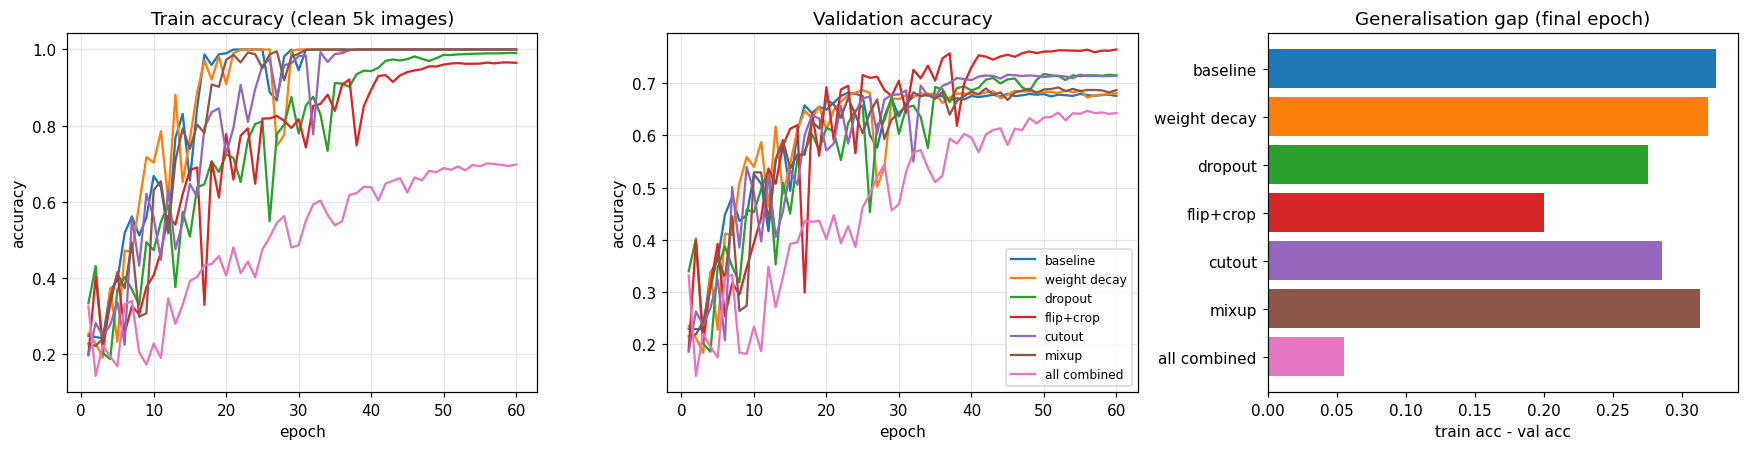

In [ ]:
reg_table = pd.DataFrame([{'setting': n,
                           'train acc': h['train_acc'][-1],
                           'val acc': h['val_acc'][-1],
                           'gap (train - val)': h['train_acc'][-1] - h['val_acc'][-1],
                           'best val acc': max(h['val_acc'])} for n, h in reg_hist.items()]).set_index('setting')
display(reg_table.style.format('{:.4f}'))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
cmap = plt.get_cmap('tab10')
for i, (n, h) in enumerate(reg_hist.items()):
    ep = range(1, len(h['val_acc']) + 1)
    ax[0].plot(ep, h['train_acc'], color=cmap(i), label=n)
    ax[1].plot(ep, h['val_acc'], color=cmap(i), label=n)
ax[0].set_title('Train accuracy (clean 5k images)'); ax[1].set_title('Validation accuracy')
for a in ax[:2]:
    a.set_xlabel('epoch'); a.set_ylabel('accuracy'); a.grid(alpha=0.3)
ax[1].legend(fontsize=8)
ax[2].barh(reg_table.index, reg_table['gap (train - val)'], color=[cmap(i) for i in range(len(reg_table))])
ax[2].invert_yaxis(); ax[2].set_xlabel('train acc - val acc'); ax[2].set_title('Generalisation gap (final epoch)')
plt.tight_layout(); plt.show()

**Discussion.** The baseline overfits badly. Train accuracy is 100%, but validation accuracy is only 67.6%, so the gap is 32 points.

* **Weight decay** has almost no effect (68.1%).
* **Dropout** helps (71.6%, gap 27.5 points).
* **Flip + crop** works best on its own. It gives the highest validation accuracy (76.5%) and cuts the gap to 20 points. The network sees new versions of each image every epoch, so it is like having more data.
* **Cutout** helps about as much as dropout (71.5%).
* **Mixup** helps only a little (68.7%). With α = 0.4, most mixed images stay close to one of the two originals.
* **All combined** gives by far the smallest gap (5.5 points), but also the lowest validation accuracy (64.3%). Train accuracy is only 69.8%, so the model underfits. Using every method together is too strong for this small network in 60 epochs.

Flip + crop is the most useful single method. Adding everything together is not always better.

### (b) Plain vs residual CIFAR networks of depth $6n+2$ (8, 20, 56)
The architecture follows He et al. (2016): a 3×3 conv with 16 channels, then 3 stages of $n$ basic blocks (two 3×3 conv + BN each) with 16 / 32 / 64 channels (stride 2 at the start of stages 2 and 3), then global average pooling and an FC layer. Kaiming initialisation, batch norm everywhere.
**The only difference between the two families is the shortcut.** The residual network uses parameter-free identity shortcuts ("option A": subsample and pad the extra channels with zeros when the size changes), so both networks have *exactly the same parameters*.
Training: SGD momentum 0.9, learning rate 0.1 (1 warm-up epoch, then cosine), weight decay $10^{-4}$, batch 128, flip + crop, 20 epochs, mixed precision.

In [ ]:
def kaiming_init(m):
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

class BasicBlock(nn.Module):
    def __init__(self, in_c, out_c, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.residual = residual
        self.stride = stride
        self.extra_c = out_c - in_c
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            sc = x
            if self.stride != 1:
                sc = sc[:, :, ::self.stride, ::self.stride]          # match the spatial size
            if self.extra_c > 0:                                       # zero-pad the extra channels
                sc = F.pad(sc, (0, 0, 0, 0, self.extra_c // 2, self.extra_c - self.extra_c // 2))
            out = out + sc
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, depth, residual):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        blocks, in_c = [], 16
        for stage, out_c in enumerate([16, 32, 64]):
            for b in range(n):
                stride = 2 if (stage > 0 and b == 0) else 1
                blocks.append(BasicBlock(in_c, out_c, stride, residual))
                in_c = out_c
        self.blocks = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, 10)
        self.apply(kaiming_init)
    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(torch.flatten(self.pool(x), 1))

for d in [8, 20, 56]:
    print(f'depth {d:2d}: plain {count_params(CifarNet(d, False)):,} params | residual {count_params(CifarNet(d, True)):,} params')

depth  8: plain 75,290 params | residual 75,290 params
depth 20: plain 269,722 params | residual 269,722 params
depth 56: plain 853,018 params | residual 853,018 params


In [ ]:
depth_hist = {}
for d in [8, 20, 56]:
    for residual in [False, True]:
        name = f'{"ResNet" if residual else "Plain"}-{d}'
        set_seed(0)
        depth_hist[name] = train_model(
            CifarNet(d, residual), Xtr, ytr, E(20),
            lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9, weight_decay=1e-4),
            bs=128, aug={'flip': True, 'crop': True}, schedule='cosine', warmup_epochs=1,
            Xv=Xva, yv=yva, verbose=True, tag=name)

Plain-8 epoch   1/20  train loss 1.7590  val acc 0.3486  (5s)
Plain-8 epoch   5/20  train loss 0.8514  val acc 0.6272  (15s)
Plain-8 epoch   9/20  train loss 0.6524  val acc 0.7434  (24s)
Plain-8 epoch  13/20  train loss 0.5417  val acc 0.7936  (33s)
Plain-8 epoch  17/20  train loss 0.4669  val acc 0.8210  (43s)
Plain-8 epoch  20/20  train loss 0.4485  val acc 0.8244  (50s)
ResNet-8 epoch   1/20  train loss 1.7669  val acc 0.4634  (2s)
ResNet-8 epoch   5/20  train loss 0.8806  val acc 0.5908  (13s)
ResNet-8 epoch   9/20  train loss 0.6845  val acc 0.7282  (23s)
ResNet-8 epoch  13/20  train loss 0.5770  val acc 0.7932  (33s)
ResNet-8 epoch  17/20  train loss 0.5005  val acc 0.8160  (43s)
ResNet-8 epoch  20/20  train loss 0.4808  val acc 0.8162  (50s)
Plain-20 epoch   1/20  train loss 1.8623  val acc 0.3150  (5s)
Plain-20 epoch   5/20  train loss 0.8406  val acc 0.7310  (26s)
Plain-20 epoch   9/20  train loss 0.6039  val acc 0.7386  (47s)
Plain-20 epoch  13/20  train loss 0.4687  val acc

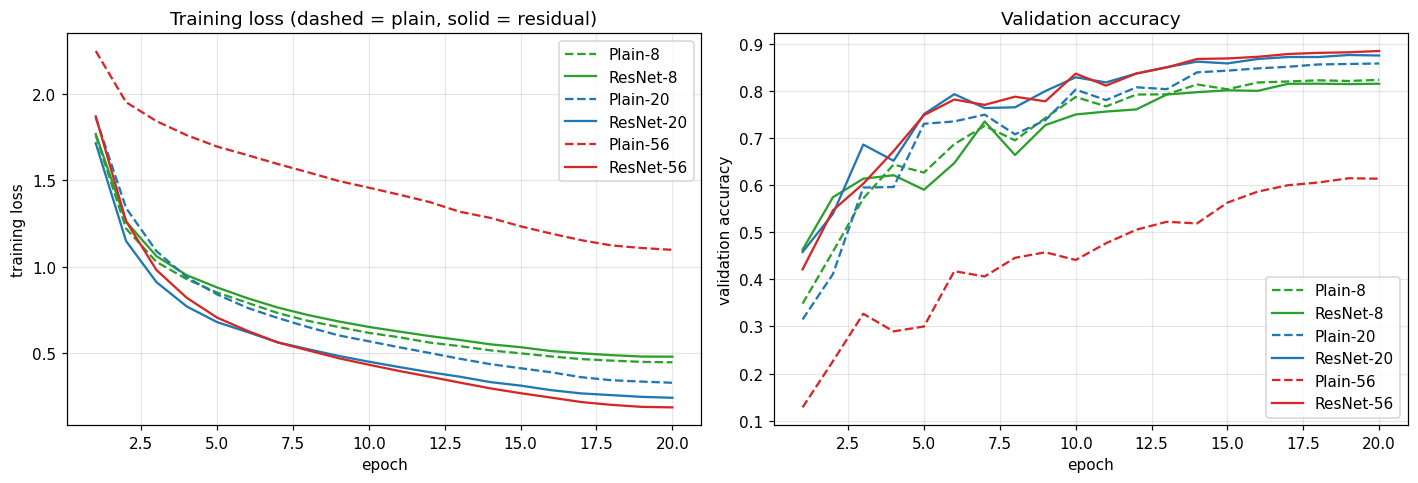

,final train loss,final val acc,time (s)
network,,,
Plain-8,0.4485,0.8244,50
ResNet-8,0.4808,0.8162,50
Plain-20,0.3301,0.8592,104
ResNet-20,0.2434,0.8762,111
Plain-56,1.0980,0.6142,279
ResNet-56,0.1879,0.8858,293


In [ ]:
depth_color = {8: 'tab:green', 20: 'tab:blue', 56: 'tab:red'}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in depth_hist.items():
    d = int(name.split('-')[1]); res = name.startswith('ResNet')
    ep = range(1, len(h['train_loss']) + 1)
    ax[0].plot(ep, h['train_loss'], ls='-' if res else '--', color=depth_color[d], label=name)
    ax[1].plot(ep, h['val_acc'], ls='-' if res else '--', color=depth_color[d], label=name)
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('training loss'); ax[0].set_title('Training loss (dashed = plain, solid = residual)')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('validation accuracy'); ax[1].set_title('Validation accuracy')
for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame([{'network': n, 'final train loss': h['train_loss'][-1], 'final val acc': h['val_acc'][-1],
                       'time (s)': h['time']} for n, h in depth_hist.items()]).set_index('network')
        .style.format({'final train loss': '{:.4f}', 'final val acc': '{:.4f}', 'time (s)': '{:.0f}'}))

**Discussion.** Plain-20 trains a little better than Plain-8 (final loss 0.33 vs 0.45). But Plain-56 is much worse. Its final training loss is 1.10 and its validation accuracy is only 61.4%. This is not overfitting, because the training loss itself is higher. The deep plain network is simply harder to train. This is called the degradation problem.

For residual networks, deeper is always better. The training loss drops from 0.48 (ResNet-8) to 0.24 (ResNet-20) to 0.19 (ResNet-56). ResNet-56 also has the best validation accuracy (88.6%). Each block only has to learn a small change on top of its input, and the shortcut lets the gradient flow straight back to the early layers.

At depth 8 the two networks are almost the same. The difference grows with depth: at depth 56, the residual network reaches 88.6% while the plain one reaches only 61.4%. Both have the same parameters, so the shortcut alone causes the difference.

---
## Task 4 (Optional): Best CNN with ≤ 500k parameters and ≤ 20 epochs

**Design.** A small ResNet-9-style network:
`conv(3→32) → conv(32→64) + maxpool → residual block(64) → conv(64→128) + maxpool → residual block(128) → global max pool → FC(128→10)`
Every conv is 3×3 + BN + ReLU. Total ≈ 465k parameters.
**Training (full model):** SGD with Nesterov momentum 0.9, peak learning rate 0.1 with a one-cycle schedule (linear warm-up for 4 epochs, then linear decay to 0), weight decay $5\times10^{-4}$, label smoothing 0.1, batch 256, flip + crop + cutout (8×8), mixed precision, **20 epochs**.

**Ablation (each change made alone, everything else kept the same):** no shortcut · no data augmentation · no weight decay · Adam (lr 1e-3) instead of SGD · no label smoothing.
Tuning is done only on the validation split. The test set is loaded and used **once**, for the final chosen model.

In [ ]:
RUN_TASK4 = True

def conv_bn(ci, co):
    return nn.Sequential(nn.Conv2d(ci, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True))

class Res(nn.Module):
    def __init__(self, c, shortcut=True):
        super().__init__()
        self.f = nn.Sequential(conv_bn(c, c), conv_bn(c, c))
        self.shortcut = shortcut
    def forward(self, x):
        return x + self.f(x) if self.shortcut else self.f(x)

class SmallResNet(nn.Module):
    def __init__(self, shortcut=True):
        super().__init__()
        self.net = nn.Sequential(
            conv_bn(3, 32),
            conv_bn(32, 64), nn.MaxPool2d(2), Res(64, shortcut),     # 16x16
            conv_bn(64, 128), nn.MaxPool2d(2), Res(128, shortcut),   # 8x8
            nn.AdaptiveMaxPool2d(1), nn.Flatten(), nn.Linear(128, 10))
        self.apply(kaiming_init)
    def forward(self, x):
        return self.net(x)

n_params = count_params(SmallResNet())
print(f'SmallResNet parameters: {n_params:,}')
assert n_params <= 500_000

SmallResNet parameters: 464,170


In [ ]:
full_cfg = dict(shortcut=True, aug={'flip': True, 'crop': True, 'cutout': 8}, wd=5e-4, opt='sgd', ls=0.1)
ablations = {
    'full model':          {},
    'no shortcut':         dict(shortcut=False),
    'no augmentation':     dict(aug={}),
    'no weight decay':     dict(wd=0.0),
    'Adam instead of SGD': dict(opt='adam'),
    'no label smoothing':  dict(ls=0.0),
}

def make_opt_t4(opt, wd):
    if opt == 'sgd':
        return lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9, nesterov=True, weight_decay=wd)
    return lambda ps: torch.optim.Adam(ps, lr=1e-3, weight_decay=wd)

t4_hist, t4_states = {}, {}
if RUN_TASK4:
    for name, change in ablations.items():
        cfg = {**full_cfg, **change}
        set_seed(0)
        model = SmallResNet(cfg['shortcut'])
        h = train_model(model, Xtr, ytr, E(20), make_opt_t4(cfg['opt'], cfg['wd']), bs=256,
                        aug=cfg['aug'], schedule='linear', warmup_epochs=4 if not QUICK else 0,
                        label_smoothing=cfg['ls'], Xv=Xva, yv=yva, verbose=False)
        t4_hist[name] = h
        t4_states[name] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f'{name:22s} final val acc {h["val_acc"][-1]:.4f}  [{h["time"]:.0f}s]')

full model             final val acc 0.9040  [81s]
no shortcut            final val acc 0.9058  [77s]
no augmentation        final val acc 0.8524  [76s]
no weight decay        final val acc 0.8780  [78s]
Adam instead of SGD    final val acc 0.8832  [80s]
no label smoothing     final val acc 0.9018  [78s]


,val acc,change vs full model,final train loss
setting,,,
full model,0.9040,+0.0000,0.7351
no shortcut,0.9058,+0.0018,0.7318
no augmentation,0.8524,-0.0516,0.5266
no weight decay,0.8780,-0.0260,0.7792
Adam instead of SGD,0.8832,-0.0208,0.8003
no label smoothing,0.9018,-0.0022,0.2036


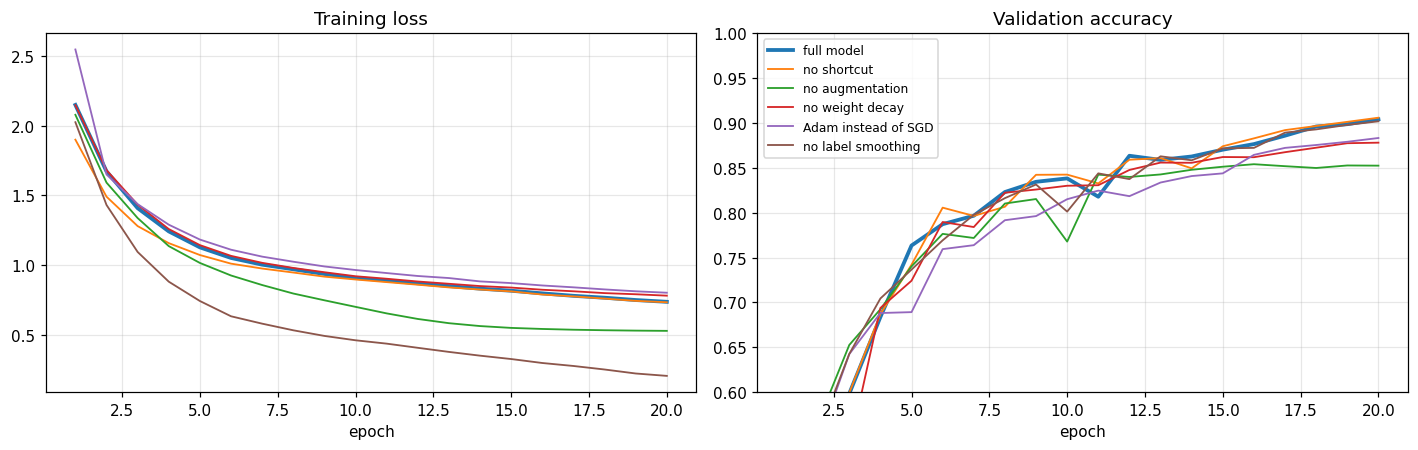

In [ ]:
if RUN_TASK4:
    base = t4_hist['full model']['val_acc'][-1]
    abl_table = pd.DataFrame([{'setting': n, 'val acc': h['val_acc'][-1], 'change vs full model': h['val_acc'][-1] - base,
                               'final train loss': h['train_loss'][-1]} for n, h in t4_hist.items()]).set_index('setting')
    display(abl_table.style.format({'val acc': '{:.4f}', 'change vs full model': '{:+.4f}', 'final train loss': '{:.4f}'}))

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for n, h in t4_hist.items():
        ep = range(1, len(h['val_acc']) + 1)
        lw = 2.5 if n == 'full model' else 1.2
        ax[0].plot(ep, h['train_loss'], lw=lw, label=n)
        ax[1].plot(ep, h['val_acc'], lw=lw, label=n)
    ax[0].set_title('Training loss'); ax[1].set_title('Validation accuracy')
    for a in ax:
        a.set_xlabel('epoch'); a.grid(alpha=0.3)
    ax[1].legend(fontsize=8); ax[1].set_ylim(0.6, 1.0)
    plt.tight_layout(); plt.show()

### Final model – test set (used once)
The final model is the setting with the highest **validation** accuracy in the ablation (normally the full model). Its trained weights are loaded and evaluated on the 10k test images **one time only**.

In [ ]:
if RUN_TASK4:
    final_name = max(t4_hist, key=lambda n: t4_hist[n]['val_acc'][-1])
    final_cfg = {**full_cfg, **ablations[final_name]}
    final_model = SmallResNet(final_cfg['shortcut']).to(device)
    final_model.load_state_dict(t4_states[final_name])

    test_ds = torchvision.datasets.CIFAR10(root, train=False, download=True)
    Xte = normalize(torch.tensor(test_ds.data).permute(0, 3, 1, 2).float().div(255)).to(device)
    yte = torch.tensor(test_ds.targets).to(device)

    test_acc, _ = evaluate(final_model, Xte, yte)        # <-- the only use of the test set
    print(f'Final model: "{final_name}"  |  parameters: {count_params(final_model):,}  |  epochs: {E(20)}')
    print(f'Validation accuracy: {t4_hist[final_name]["val_acc"][-1]:.4f}')
    print(f'TEST accuracy:       {test_acc:.4f}')

Final model: "no shortcut"  |  parameters: 464,170  |  epochs: 20
Validation accuracy: 0.9058
TEST accuracy:       0.8955


**Discussion.** The best setting on the validation set was "no shortcut" (90.6%), so it was chosen as the final model. It reached **89.55% test accuracy** with 464k parameters in 20 epochs. The test accuracy is close to the validation accuracy, so the validation split gave a fair estimate.

* **No augmentation** causes the biggest drop (−5.2 points).
* **No weight decay** gives the second biggest drop (−2.6 points).
* **Adam** does worse than SGD with momentum (−2.1 points).
* **No label smoothing** gives only a small drop (−0.2 points).
* **No shortcut** gives almost the same result (+0.2 points). This network has only 8 conv layers, so it trains well even without shortcuts. This matches Task 3(b), where shortcuts mattered only for deep networks. A 0.2-point difference is also small enough to be random noise.

Augmentation and weight decay matter the most for this model.

---
## Summary

* **Task 1:** The hand-written gradients matched autograd and finite differences. The MLP reached about 50% validation accuracy. In a deep MLP, sigmoid caused vanishing gradients, while ReLU did not.
* **Task 2:** The custom optimizers matched PyTorch. On the quadratic, SGD zig-zagged, momentum moved faster along the valley, and Adam went more directly to the minimum. Each optimizer needed its own learning rate.
* **Task 3:** With 5k images, flip + crop reduced overfitting the most. Using all methods together was too strong and made the model underfit. Deep plain networks were hard to train, but residual networks improved with depth.
* **Task 4:** A ResNet-style network with about 464k parameters reached 89.55% test accuracy in 20 epochs. Augmentation and weight decay had the largest effect. The shortcut made little difference in this shallow network.

Overall, good gradient flow, a suitable learning rate and data augmentation were the key factors.